# Importa Bibliotecas

In [105]:
import pandas as pd
import numpy as np
import sklearn as skl
import seaborn as sns

from xgboost import XGBClassifier

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix, classification_report

## Constantes

In [106]:
TARGET = 'is_fraud'

## Carrega Dados

In [107]:
df_train = pd.read_csv('data/train.csv')
df_test = pd.read_csv('data/test.csv')

## Tratando dados

In [108]:
def transform_data(df_1 : pd.DataFrame, df_2 : pd.DataFrame):
    
    ids = df_2['id']
    targets = df_1[TARGET].reset_index()
    df = pd.concat([df_1, df_2], axis='index').drop(columns=[TARGET, 'id'])

    bool_columns = list(df.select_dtypes(['bool']).columns)
    numeric_columns = list(df.select_dtypes(['number']).columns)
    string_columns = list(df.select_dtypes(['string', 'object']).columns)

    df[bool_columns] = df[bool_columns].astype('int32')

    preprocess = ColumnTransformer(
        transformers = [
            ("num", StandardScaler(), numeric_columns),
            ("str", OneHotEncoder(handle_unknown='ignore', sparse_output=False), string_columns)
        ],
        remainder='passthrough'
    )

    df = preprocess.fit_transform(df)
    names = preprocess.get_feature_names_out()
    df = pd.DataFrame(data=df, columns=names)
    df = pd.concat([df, targets[TARGET]], axis=1)

    return ids, df

In [109]:
ids, df = transform_data(df_train, df_test)

## Analise explotratoria de dados

In [110]:
print(df.shape)

(999944, 55)


In [111]:
df

,num__amount_usd,num__hours_since_last_txn,num__txn_count_last_24h,num__distance_from_home_km,num__card_age_months,num__customer_age,num__account_balance_usd,num__cvv_retry_count,num__velocity_score,num__time_of_day_hour,...,str__device_type_Tablet,str__device_type_Windows PC,str__device_type_iPhone,remainder__is_foreign_transaction,remainder__is_new_merchant,remainder__used_vpn,remainder__ip_country_mismatch,remainder__billing_shipping_mismatch,remainder__is_ai_generated_scam_attempt,is_fraud
0,-0.091788,0.497909,-1.323864,0.360545,0.204879,0.255436,-0.233957,-0.295240,-1.236175,0.763141,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,-0.269716,-0.809496,0.010672,-0.045816,-1.586508,-1.309079,0.342041,-0.295240,1.331491,1.636536,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,-0.360174,-0.863508,0.677940,-0.466813,0.563156,0.199561,-0.299215,-0.295240,1.552366,0.472009,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,-0.207958,-0.239195,0.677940,-0.423766,0.204879,-0.191568,0.044214,-0.295240,0.162697,-0.692519,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2.810950,-0.927051,0.677940,-0.163764,-1.765646,0.031934,0.359072,-0.295240,1.460335,-1.129217,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
999939,-0.261292,-0.342452,-1.991132,-0.418601,-0.690814,0.534814,-0.460714,3.160255,-1.539877,0.472009,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN
999940,-0.351065,-0.628398,1.345209,-1.065163,-1.228230,-0.694448,0.190730,-0.295240,-0.067380,-1.129217,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,NaN
999941,-0.172108,-0.361516,0.677940,1.885259,-0.511676,-1.364954,-0.079008,3.160255,1.064601,1.199839,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN
999942,-0.373643,-0.777725,0.010672,0.281339,-1.228230,-1.309079,0.417325,-0.295240,-0.720801,-1.274782,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN


In [112]:
s = df.corr(numeric_only=True)['is_fraud'].sort_values()

In [113]:
s

str__auth_method_Biometric                -0.035897
str__auth_method_PIN                      -0.033238
str__merchant_category_Online Retail      -0.023383
str__merchant_category_Groceries          -0.022035
num__hours_since_last_txn                 -0.020490
str__merchant_category_Restaurants        -0.016907
str__auth_method_OTP                      -0.011875
str__merchant_category_Fuel               -0.010323
str__auth_method_3D Secure                -0.009962
str__merchant_category_Healthcare         -0.006942
str__merchant_category_Utilities          -0.005671
str__card_type_Mastercard                 -0.003985
str__channel_Contactless                  -0.003825
str__device_type_Android Phone            -0.003329
str__card_type_Discover                   -0.002649
str__device_type_Windows PC               -0.001588
str__channel_ATM                          -0.001353
str__channel_In-App                       -0.001066
str__channel_POS                          -0.000486
num__time_of

In [114]:
def get_colunas_com_correlacao_direta_ao_target(s : pd.Series, similaridade : float):
    return list(s.loc[abs(s) >= similaridade].index)

In [115]:
baixa_similaridade = get_colunas_com_correlacao_direta_ao_target(s, 0.001)

In [116]:
df = df[baixa_similaridade]
list(df.columns)

['str__auth_method_Biometric',
 'str__auth_method_PIN',
 'str__merchant_category_Online Retail',
 'str__merchant_category_Groceries',
 'num__hours_since_last_txn',
 'str__merchant_category_Restaurants',
 'str__auth_method_OTP',
 'str__merchant_category_Fuel',
 'str__auth_method_3D Secure',
 'str__merchant_category_Healthcare',
 'str__merchant_category_Utilities',
 'str__card_type_Mastercard',
 'str__channel_Contactless',
 'str__device_type_Android Phone',
 'str__card_type_Discover',
 'str__device_type_Windows PC',
 'str__channel_ATM',
 'str__channel_In-App',
 'num__account_balance_usd',
 'num__distance_from_home_km',
 'str__device_type_POS Terminal',
 'str__card_type_Visa',
 'str__device_type_iPhone',
 'str__merchant_category_Travel',
 'num__day_of_week',
 'str__channel_Online',
 'str__card_type_Amex',
 'str__merchant_category_Streaming',
 'num__amount_usd',
 'num__prior_disputes',
 'str__merchant_category_Electronics',
 'str__merchant_category_Crypto Exchange',
 'str__merchant_categor

## Train test split

In [117]:
df_train = df[:len(df_train)]
df_test = df[len(df_train):]

In [118]:
x = df_train.drop(columns=TARGET)
y = df_train[TARGET]

x_train, x_temp, y_train, y_temp = train_test_split(x, y, test_size=0.005, shuffle=True, random_state=42, stratify=y)
x_test, x_val, y_test, y_val = train_test_split(x_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

print(x_train.shape, x_val.shape, x_test.shape)

(696460, 46) (1750, 46) (1750, 46)


In [119]:
params = {
    'n_estimators': 1000,
    'max_depth': 9,
    'eval_metric': 'auc',
    'learning_rate': 0.09918802139540925,
    'subsample': 0.6684329833808584,
    'colsample_bytree': 0.9151036654152414,
    'gamma': 0.14911870890152207,
    'reg_alpha': 0.10085071428350272,
    'reg_lambda': 0.6724424529145199,
    'min_child_weight': 2,
    'n_jobs': -1,
    'early_stopping_rounds': 20
}

xgb_clf = XGBClassifier(**params)
xgb_clf.fit(x_train, y_train, eval_set = [(x_val, y_val)])

[0]	validation_0-auc:0.88337
[1]	validation_0-auc:0.91638
[2]	validation_0-auc:0.92340
[3]	validation_0-auc:0.92532
[4]	validation_0-auc:0.93035
[5]	validation_0-auc:0.92755
[6]	validation_0-auc:0.92794
[7]	validation_0-auc:0.92608
[8]	validation_0-auc:0.92511
[9]	validation_0-auc:0.92585
[10]	validation_0-auc:0.92810
[11]	validation_0-auc:0.92903
[12]	validation_0-auc:0.92736
[13]	validation_0-auc:0.92698
[14]	validation_0-auc:0.92796
[15]	validation_0-auc:0.92927
[16]	validation_0-auc:0.93129
[17]	validation_0-auc:0.93148
[18]	validation_0-auc:0.93135
[19]	validation_0-auc:0.93183
[20]	validation_0-auc:0.93145
[21]	validation_0-auc:0.93114
[22]	validation_0-auc:0.93157
[23]	validation_0-auc:0.93211
[24]	validation_0-auc:0.93174
[25]	validation_0-auc:0.93144
[26]	validation_0-auc:0.93204
[27]	validation_0-auc:0.93234
[28]	validation_0-auc:0.93302
[29]	validation_0-auc:0.93486
[30]	validation_0-auc:0.93488
[31]	validation_0-auc:0.93490
[32]	validation_0-auc:0.93622
[33]	validation_0-au

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.9151036654152414
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",20
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'auc'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


<Axes: >

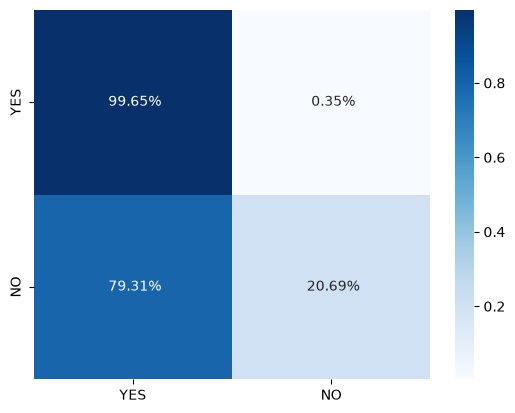

In [120]:
y_pred = xgb_clf.predict(x_test)
y_pred
cm = confusion_matrix(y_test, y_pred, normalize='true')

sns.heatmap(
    cm,
    cmap='Blues',
    fmt =" .2%",
    annot=True,
    xticklabels=["YES", "NO"],
    yticklabels=["YES", "NO"]
)

In [ ]:
df_test = df_test.drop(columns=['is_fraud'])
out = xgb_clf.predict_proba(df_test)[:,1]
out
df_final = pd.DataFrame(
    {
        "id": ids,
        "is_fraud": out
    }
)
df_final.to_csv("solved_03.csv", index=False)